# Remote Sensing & Cloud Detection EDA Notebook (Lab 2)

#### **Problem:**  Clouds in the Arctic are extremely difficult to distinguish from the Earth's surface. 

- hard to distinguish a cloud from snow surfaces since both are similar in color temperatures. (can't use color or temperature to tell them apart)

#### **Objective:** Classify every individual pixel as a clour or not-cloud. (unit of analysis: each pixel)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics
import sklearn

# Loading the Data & Initial Thoughts

How I formed the data: 
- Of the 3/164 labeled files appears to be an array with 11 columns and 114973 rows, this constitutes one image from the satelite. The "x" & "y" columns are the image coordinates with the "NDAI", "SD", & "COOR" being features developed by the domain experts.



In [3]:
npz_files = ["../data/O012791.npz", '../data/O013257.npz', '../data/O013490.npz']
data = np.load( "../data/O012791.npz")
print(data.files)

data[data.files[0]]

['arr_0']


array([[2.00000000e+00, 7.00000000e+01, 2.69479662e-01, ...,
        1.87100000e+04, 1.78215000e+04, 0.00000000e+00],
       [2.00000000e+00, 7.10000000e+01, 2.59262085e-01, ...,
        1.98120000e+04, 1.70447500e+04, 0.00000000e+00],
       [2.00000000e+00, 7.20000000e+01, 2.06566125e-01, ...,
        1.95187500e+04, 1.66635000e+04, 0.00000000e+00],
       ...,
       [3.83000000e+02, 3.66000000e+02, 1.16337225e-01, ...,
        2.39572500e+04, 2.27045000e+04, 0.00000000e+00],
       [3.83000000e+02, 3.67000000e+02, 1.26903161e-01, ...,
        2.45055000e+04, 2.26155000e+04, 0.00000000e+00],
       [3.83000000e+02, 3.68000000e+02, 1.29656285e-01, ...,
        2.47815000e+04, 2.25295000e+04, 0.00000000e+00]],
      shape=(114973, 11))

Because these are arrays that contain multiple column vectors. I transformed each file into its own dataframe. I used the column names described in the documentation.

In [5]:
cols = ['y', 'x', 'NDAI', 'SD', 'CORR', 'DF', 'CF', 'BF', 'AF', 'AN', 'label']
npz_files = ["../data/O012791.npz", '../data/O013257.npz', '../data/O013490.npz']

# Make dataframe for each file
dfs = []
for f in npz_files:
    data = np.load(f)
    arr = data[data.files[0]]  
    df = pd.DataFrame(arr, columns=cols)
    dfs.append(df)

df_2791 = dfs[0]  
df_3257 = dfs[1]  
df_3490 = dfs[2]  


# Data Cleaning/Validation

Checking for any initial null or object types within each of the newly generated dataframes. I created 1 dataframe for each of the 3 files that have an expert labels & made a concated version (one big combined df)

There are no inconsistencies, null values, or duplicate rows.

In [6]:
eda_df = pd.concat([df_3490,df_3257,df_2791])
clouds_df = eda_df[eda_df['label'] == 1]
clear_df = eda_df[eda_df['label'] == -1]
eda_df.info()

<class 'pandas.DataFrame'>
Index: 345005 entries, 0 to 114972
Data columns (total 11 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   y       345005 non-null  float64
 1   x       345005 non-null  float64
 2   NDAI    345005 non-null  float64
 3   SD      345005 non-null  float64
 4   CORR    345005 non-null  float64
 5   DF      345005 non-null  float64
 6   CF      345005 non-null  float64
 7   BF      345005 non-null  float64
 8   AF      345005 non-null  float64
 9   AN      345005 non-null  float64
 10  label   345005 non-null  float64
dtypes: float64(11)
memory usage: 31.6 MB


In [7]:
print(df_2791.isna().sum().sum())
print(df_3257.isna().sum().sum())
print(df_3490.isna().sum().sum())
print(eda_df.isna().sum().sum)

0
0
0
<bound method Series.sum of y        0
x        0
NDAI     0
SD       0
CORR     0
DF       0
CF       0
BF       0
AF       0
AN       0
label    0
dtype: int64>


No duplicated values

In [8]:
print(df_2791.duplicated().sum())
print(df_3257.duplicated().sum())
print(df_3490.duplicated().sum())
print(eda_df.duplicated().sum())

0
0
0


0


Checking for inconsistencies in the labels 
- there aren't any.

In [9]:
eda_df['label'].value_counts()

label
 0.0    137324
-1.0    126716
 1.0     80965
Name: count, dtype: int64

Validating the engineered feautres.

The three physical features for creating the scatterplots are the **CORR** (correlation of the ice & snow-covered surfaces), **SD** of the MISR nadir camera pixel values & **NDAI** (normalized difference angular index) which characterizes the changes in a scene with changes in the MISR Direction.

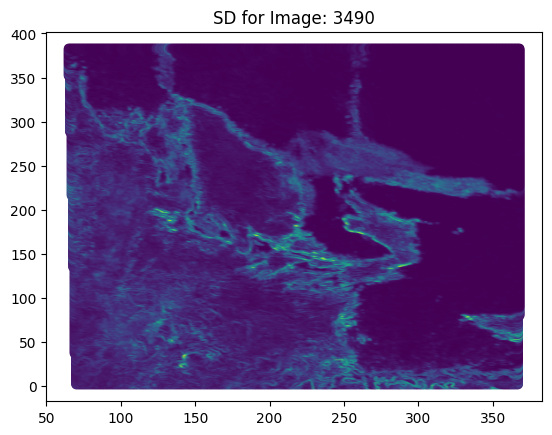

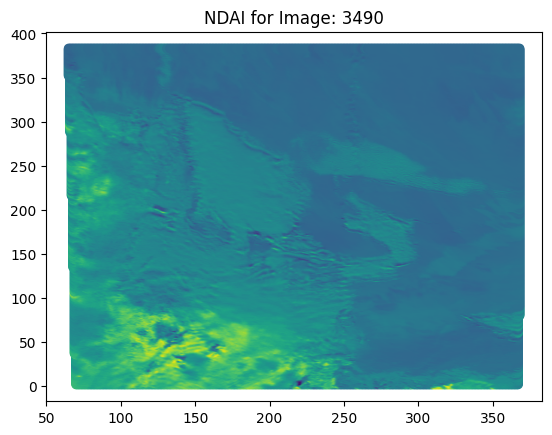

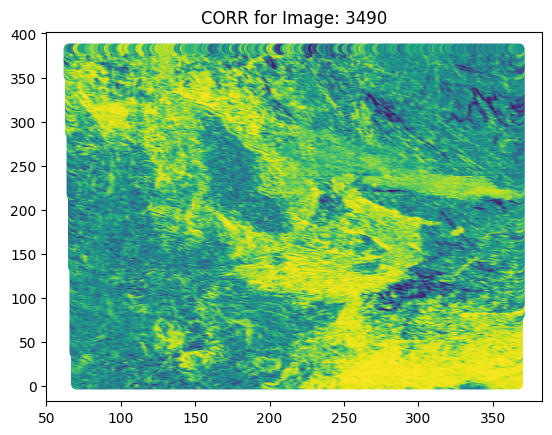

In [10]:
# Plot the 3 Engineered Features to check for any inconsistencies in points versus engineered 
def plot_features(df, title, feature="sd"):
    y_coord = df['y']
    x_coord = df['x']

    if feature == "sd":
        f = df['SD']
    elif feature == "ndai":    
        f = df['NDAI']
    elif feature == "corr":    
        f = df['CORR']
    else:
        raise ValueError(
            f"Unknown feature '{feature}'. Choose from: 'sd', 'ndai', 'corr'"
        )
    plt.scatter(x_coord, y_coord, c=f)
    plt.title(f'{feature.upper()} for Image: {title}')
    plt.show()

plot_features(df_3490, "3490", feature="sd")
plot_features(df_3490, "3490", feature="ndai")
plot_features(df_3490, "3490", feature="corr")

Creating scatterplots using the Expert Labeles for each of the three images. 

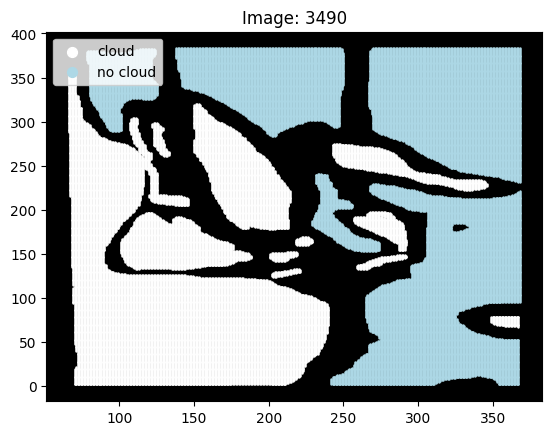

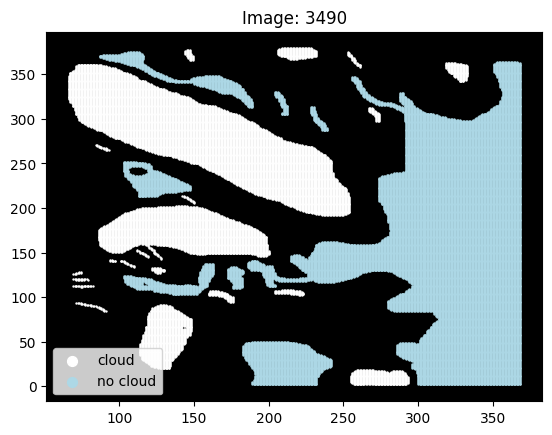

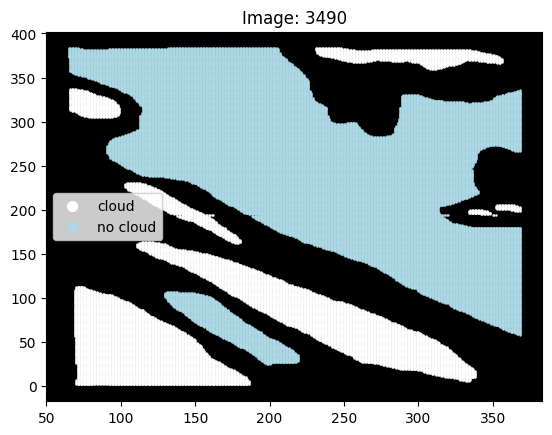

In [11]:
def plot_expert_labels(df, title):
    # remove rows where cloud detection is uncertain
    label = df[df["label"] != 0]
    cloud = label[label["label"] == 1]
    no_cloud = label[label["label"] == -1]

    plt.scatter(x=cloud['x'], y = cloud['y'], s=0.5, c="white", label="cloud")
    plt.scatter(x=no_cloud['x'], y = no_cloud['y'], s= 0.5, c="lightblue", label="no cloud")
    #plt.style.use('dark_background')
    plt.gca().set_facecolor("black")
    plt.title(f'Image: {title}')
    plt.legend(markerscale=10)
    plt.show()

plot_expert_labels(df_3490, "3490")
plot_expert_labels(df_2791, "3490")
plot_expert_labels(df_3257, "3490")

After creating scatter plots for the Expert Labels & 3 article defined useful features (SD, CORR, NDAI), I will now explore how the radiances  angles relate to each of these images. The radiances are the raw light measurements the satellite captured.

# 2. Exploratory Data Analysis

### Goal: Discover which of these 8 measurements carries the most signal about height 
(height is the fundamental difference between cloud & the surface below it)

### **Further explanation of the features:**
- Two types of features:
    - Raw Sensor Readings [DF, CF,BF, AF, AN] --> Multiple Cameras pointing at different angles simutaneously 
        - **AN** --> Straight down (0 degree, baseline "normal" phtograph looking directly at the surface below)
        - **AF** & AB --> Forward & Backward at a moderate angle ("F" forward, "B" backward relatice to the flight direction)
        - **CF** & CB --> Same idea ^ but steeper angle (seeing ground at more of an oblique view)
        - **DF** & DB --> Most extreme angle, nearly looking sideways (most oblique view of anything else)
        - Our data only consists of the forward facing camera angles.
        - Importance --> think of looking at a fluffy cload versus a flat snow surface, from the side versus from above
            - clouds look very different in depth compared to snow surfaces as the angle of the camera switches (hypoth)
        - Reason for MISR --> you can distinguish snow & clouds by how they look from multiple angles simultaneously. 

    - Engineered Features Derived from the Raw Readings
        - created to capture that pattern of chance across AN (base angle) to DF (most oblique) in one single number.
        - **CORR** --> correlation between the different camera angles across a small patch (x,y)
            - low --> clouds being puffy & in 3D look qute different from different angles
            - high --> yields a more flatter object as the texture pattern stays consistent from the different angles
            - 
            - **Question asking** --> Do the cameras see the exact same structural patterns?
        - **SD** --> standard deviation of the radiance values across the angles
            - how much the brightness varies across the different camera views given a pixel 
             - low --> not too far a part from each other so generally the points are on the same flat surface
             - high --> the brightness varies highly so the surface has more depth (3D --> cloud?)
        - **NDAI** (Normalized Difference Angular Index) --> Captures the magnitude of the angular differences between radiance values (normalizing that comparison into a single score) 
            - measures the angular signature of height 
            - things at altitude (clouds) have a distinctive pattern of how their apparent brightness changes with viewing angle compared to things on the surface. *"how cloud-like is this pixel's angular profile."*
            - things at different altitudes reflect light differently across angles.
                - *"Is this pixel's angular reflection pattern look close to the surface or up in the sky?*
            -  (question in EDA how does this number change based on clouds versus no cloud)
            - this engineered feature helps combat the fact that we cannont use color & temperature as signals & uses geomeric information about the altitude instead.

## Step 1: Plot the Expert Labels 

- This column is only included in these 3 images out of the entire dataset.

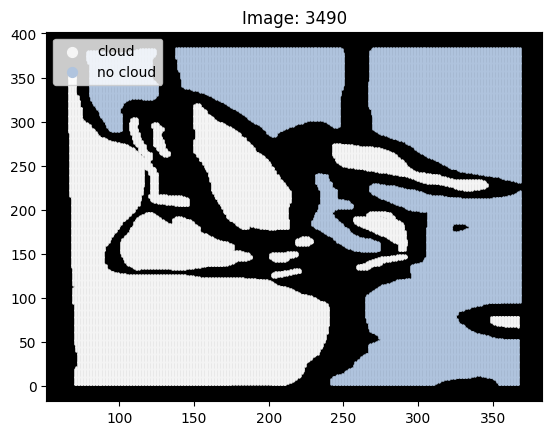

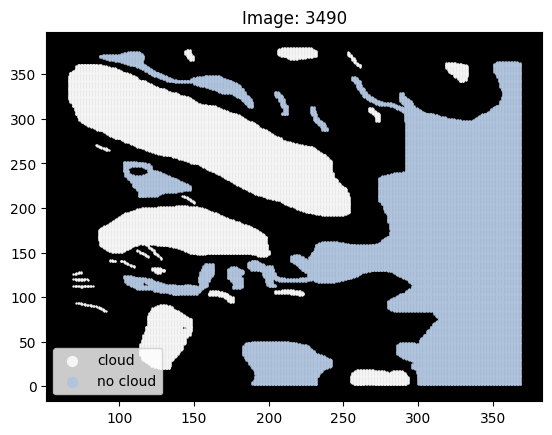

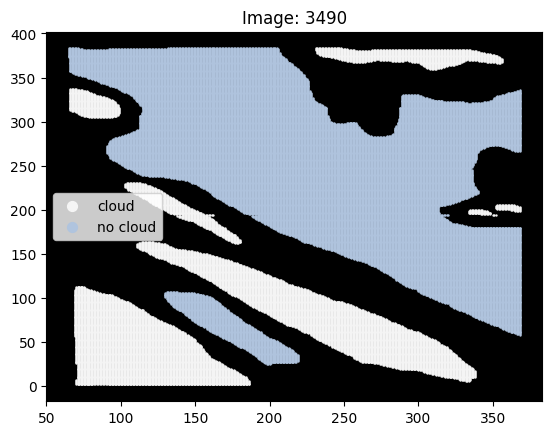

In [12]:
def plot_expert_labels(df, title):
    # remove rows where cloud detection is uncertain
    label = df[df["label"] != 0]
    cloud = label[label["label"] == 1]
    no_cloud = label[label["label"] == -1]

    plt.scatter(x=cloud['x'], y = cloud['y'], s=0.5, c="whitesmoke", label="cloud")
    plt.scatter(x=no_cloud['x'], y = no_cloud['y'], s= 0.5, c="lightsteelblue", label="no cloud")
    #plt.style.use('dark_background')
    plt.gca().set_facecolor("black")
    plt.title(f'Image: {title}')
    plt.legend(markerscale=10)
    plt.show()

plot_expert_labels(df_3490, "3490")
plot_expert_labels(df_2791, "3490")
plot_expert_labels(df_3257, "3490")

## Step 2: Exploring the Relationships Between Features & Radiance Angles

Original Feature Main Takeaways:
- NDAI — engineered specifically to capture angular height signatures
- SD — captures surface texture and 3D structure through radiance variability
- AF/AN/BF — capture the flat ground signature through consistent nadir/near-nadir brightness
- CF/DF - capture more curvatures as they are at an oblique angle

### **1. Correlation Heatmap of features given Cloud and No Cloud**
#### Relationships between features within each class (Cloud & Clear)

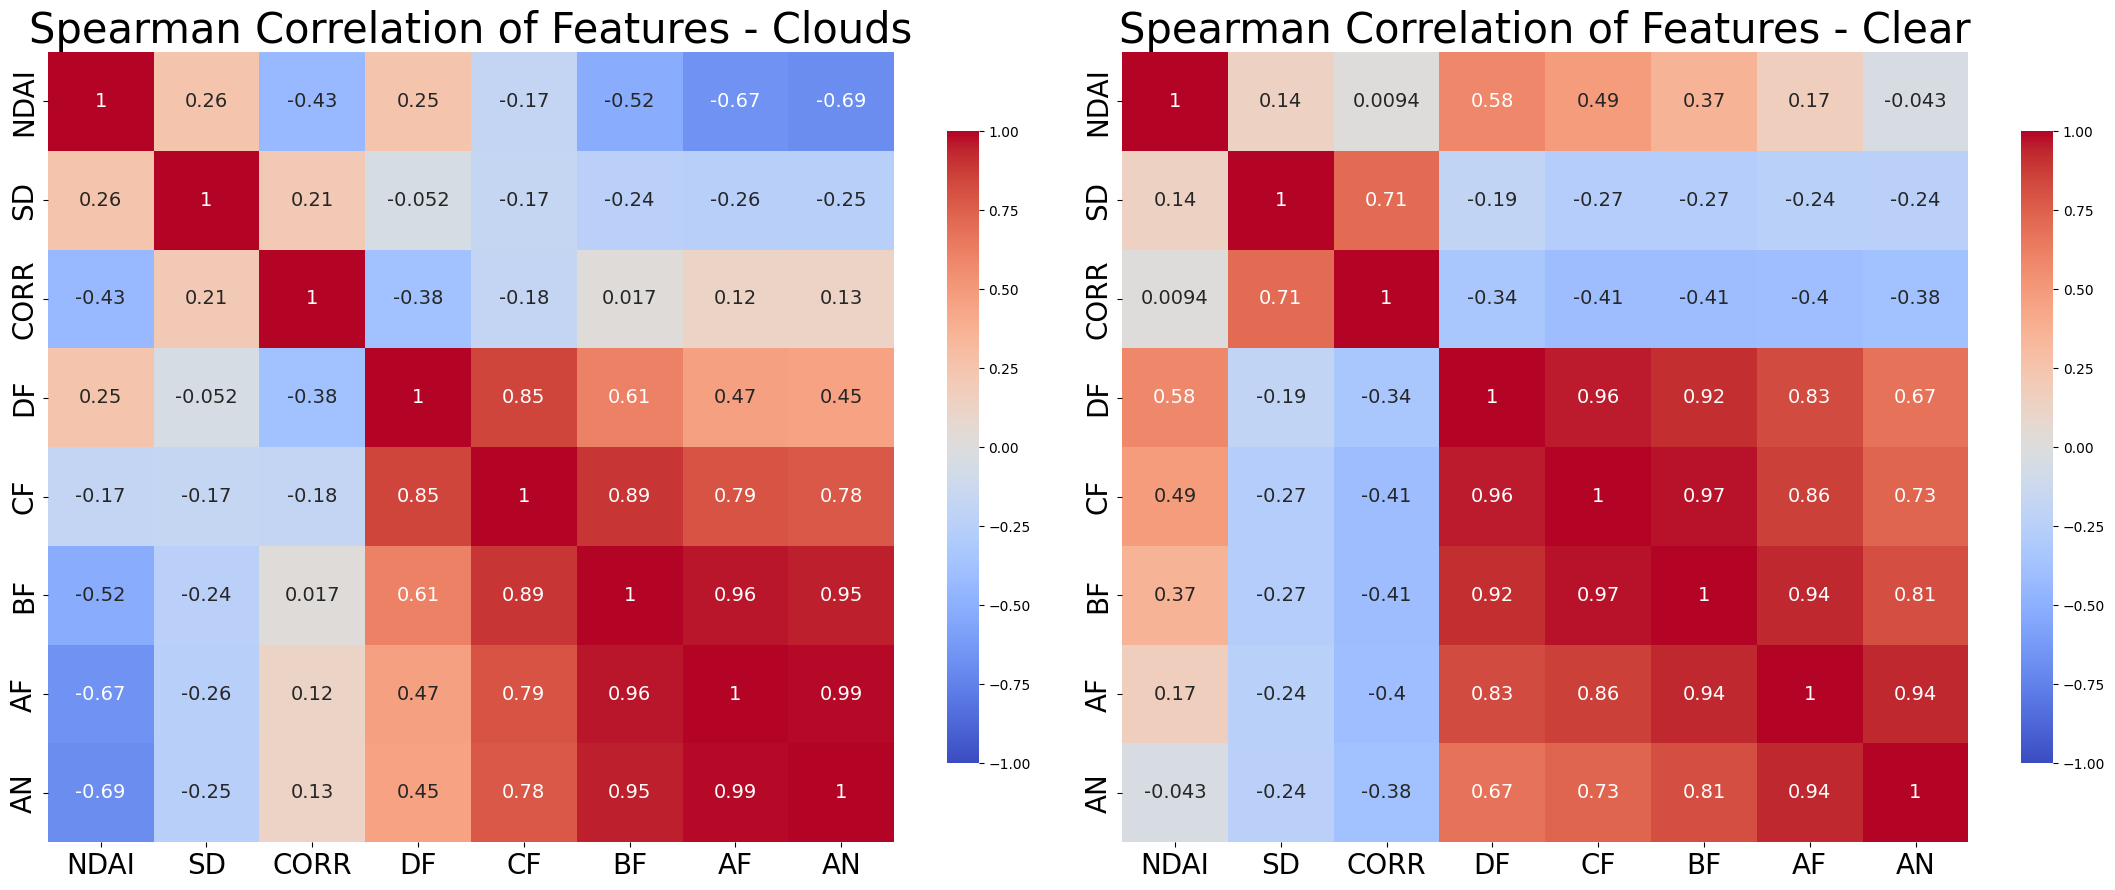

In [29]:
# Using spearman correlation b/c data is not normal
features = ['NDAI', 'SD', 'CORR', 'DF', 'CF', 'BF', 'AF', 'AN']
correlation_clouds = clouds_df[features].corr(method='spearman')
correlation_no_clouds = clear_df[features].corr(method='spearman')

# look into this.
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, corr, title in zip(axes,
                            [correlation_clouds, correlation_no_clouds],
                            ["Clouds", "Clear"]):
    sns.heatmap(corr, cmap="coolwarm", annot=True, center=0,
                vmin=-1, vmax=1, ax=ax,
                annot_kws={"size": 14},   # numbers inside heatmap cells
                cbar_kws={"shrink": 0.8})
    ax.set_title(f"Spearman Correlation of Features - {title}", fontsize=30)
    ax.tick_params(axis='both', labelsize=20)  # row and column labels

plt.tight_layout()
plt.show()


We see multicollinearity and it matters differently depending on the model:
- For interpretable models like logistic regression — multicollinearity is a real problem. It makes coefficients unstable and hard to interpret. You'd want to drop one of a highly correlated pair.
- For tree based models like random forest — less of a problem. The model will just pick one of the correlated features and downweight the other naturally.
- For neural networks — essentially not a problem at all.

### **2. Kernal Density Estimation Plot:**
- non-parametric method used to estimate the PDF of a continuous variable.

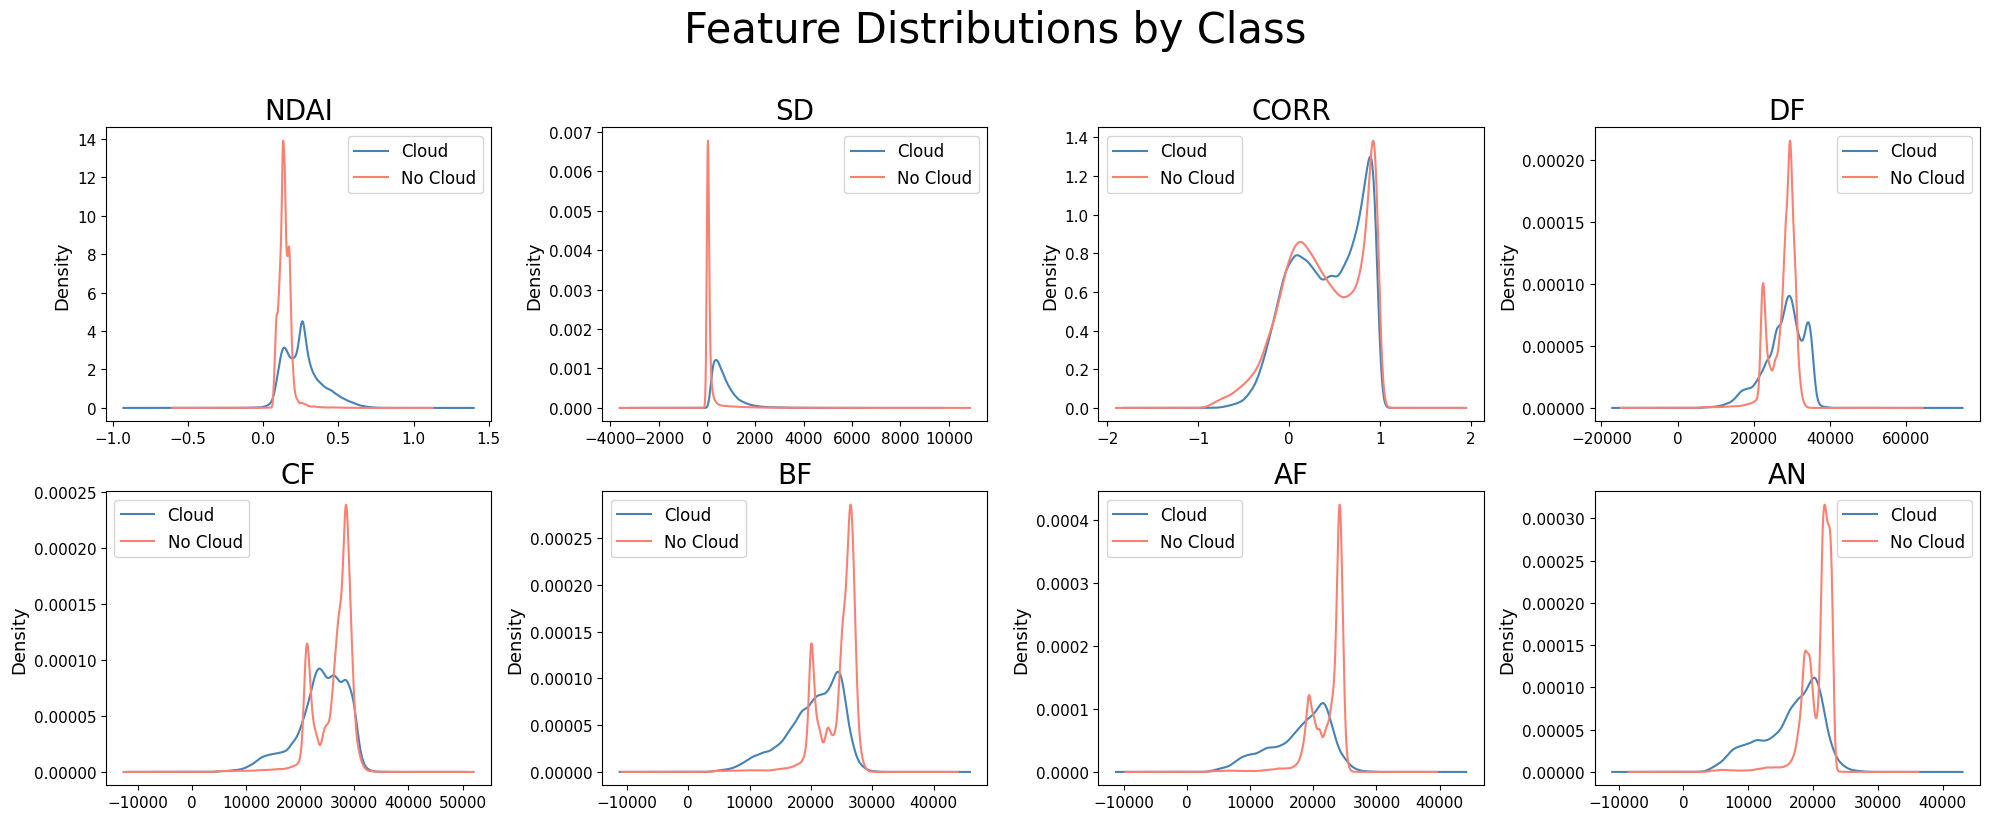

In [31]:
features = ['NDAI', 'SD', 'CORR', 'DF', 'CF', 'BF', 'AF', 'AN']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, feat in zip(axes.flatten(), features):
    for label, color, name in [(1, 'steelblue', 'Cloud'), (-1, 'salmon', 'No Cloud')]:
        subset = eda_df[eda_df['label'] == label][feat]
        subset.plot.kde(ax=ax, label=name, color=color)
    ax.set_title(feat, fontsize=20)
    #ax.set_xlabel(feat, fontsize=20)
    ax.set_ylabel("Density", fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    ax.legend(fontsize=12)

plt.suptitle("Feature Distributions by Class", y=1.02, fontsize=30)
plt.tight_layout()
plt.show()

### **3. Box Plot**

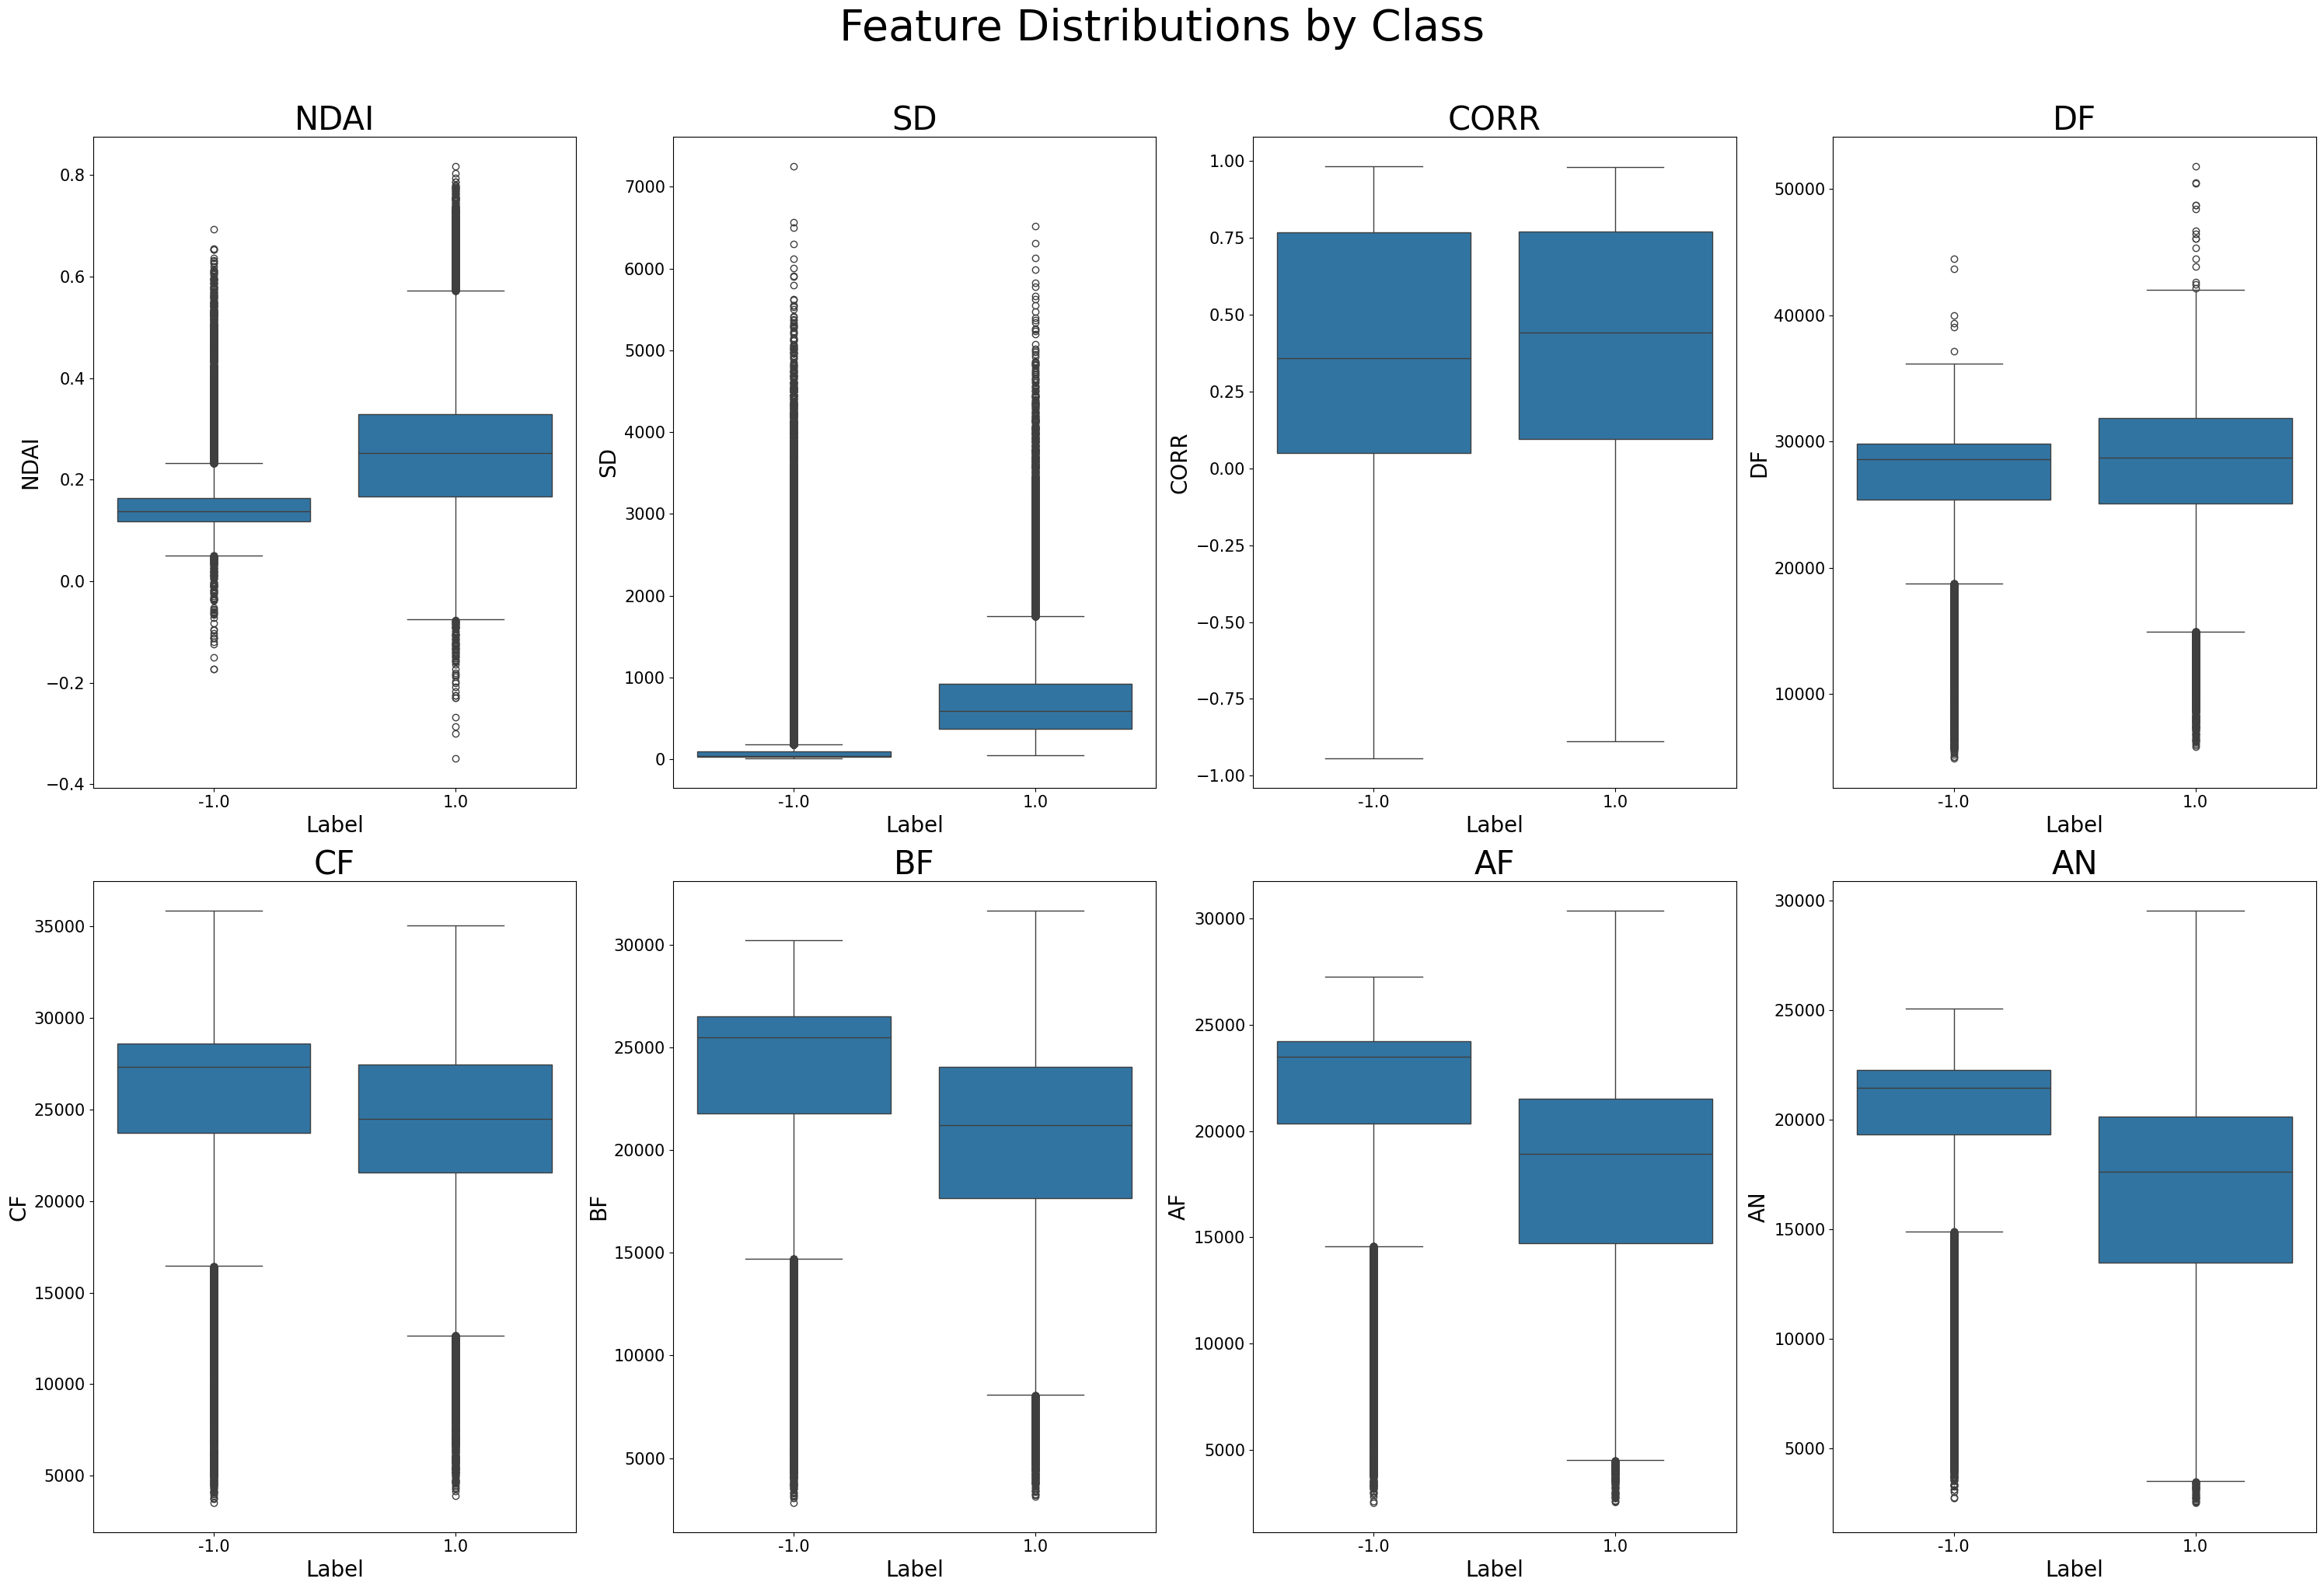

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(30, 20))
for ax, feat in zip(axes.flatten(), features):
    sns.boxplot(data=eda_df[eda_df['label'] != 0], x='label', y=feat, ax=ax)
    ax.set_title(feat, fontsize=30)
    ax.set_xlabel("Label", fontsize=20)
    ax.set_ylabel(feat, fontsize=20)
    ax.tick_params(axis='both', labelsize=15)

plt.suptitle("Feature Distributions by Class", y=1.02, fontsize=40)
plt.tight_layout()
plt.show()

### Evaluating Individual Feature Predictive Ability

I will now run various tests to see how well an individual feature predicts cloud/no cloud.

In [16]:
# Exploring Quantitative distribution of cloud & no cloud
print(f'length of clouds: {len(clouds_df)}')
print(f'length of no clouds: {len(clear_df)}')

print(f'\nProportion of clouds to clear: {len(clouds_df)/len(clear_df):.2f}')


print(f'\nSummary of Clouds df: \n{clouds_df['SD'].describe()}')
print(f'\nSummary of Clear df: \n{clear_df['SD'].describe()}')

length of clouds: 80965
length of no clouds: 126716

Proportion of clouds to clear: 0.64

Summary of Clouds df: 
count    80965.000000
mean       723.741661
std        529.914618
min         44.707161
25%        366.584778
50%        585.036194
75%        918.170288
max       6516.280273
Name: SD, dtype: float64

Summary of Clear df: 
count    126716.000000
mean        163.763015
std         443.071977
min          13.329613
25%          30.682966
50%          42.260296
75%          91.047352
max        7251.009277
Name: SD, dtype: float64


The presence of extreme outliers in both classes distorts variance comparisons — the median SD for cloud pixels is 14x higher than clear pixels, yet variance-based metrics suggest only 1.43x difference. This further motivates our use of robust nonparametric measures throughout our analysis (AUC & glass delta). --> This was also illustrated in the box plot figure above.

## Two Measures I will use to assess these individual features:

**AUC** tells us which feature is most useful for classification.
**Glass Delta** tells us how different are cloud and clear pixels on each feature? 

### Univariate Measure 1: AUC-ROC (Univaraite Analysis)

I want to test how well does each feature actually separate the two classes in the real data.

"if I picked one random cloud pixel and one random no-cloud pixel, how often does this feature correctly rank the cloud pixel higher?"

In [17]:
from sklearn.metrics import roc_auc_score
d = eda_df[eda_df["label"] != 0]
f = d["label"]

results = []

for feat in features:
    feature = d[feat]
    score = roc_auc_score(f, feature)
    score = max(score, 1 - score)
    results.append(score)
    

data= {"Feature": features, "Score":results}
df = pd.DataFrame(data)

df.sort_values(by=['Score'], ascending=False)

,Feature,Score
1,SD,0.935122
0,NDAI,0.823382
6,AF,0.799156
7,AN,0.793544
5,BF,0.770345
4,CF,0.642784
3,DF,0.554394
2,CORR,0.523656


### Univariate Measure 2: Glass Delta Score

- More accurate measure of effect size when the standard deviations of the two groups are significantly different (cloud v. clear SD's are different)
- Tells us an interpretable effect size of each feature based within each class.

In [18]:
# Calculating Glass Delta (omit using Cohen's d to correct for the varying magnitudes of each class)

results_d = []

for feat in features:
    mean_cloud = clouds_df[feat].mean()
    mean_nocloud = clear_df[feat].mean()
    
    std_cloud = clouds_df[feat].std()
    std_nocloud =  clear_df[feat].std()
    
    # glass delta
    d = (mean_cloud - mean_nocloud) / std_nocloud
    
    results_d.append(round(d, 3))

data_g= {'Feature': features, 'Glass Delta':results_d}
glass_df = pd.DataFrame(data_g)

glass_df


,Feature,Glass Delta
0,NDAI,2.816
1,SD,1.264
2,CORR,0.111
3,DF,0.156
4,CF,-0.612
5,BF,-1.143
6,AF,-1.485
7,AN,-1.602


- Positive & larger magnitude:

    - cloud pixels tend to have higher values for this feature, and the difference is large relative to typical clear pixel variation. NDAI x log(SD) at 3.220 means cloud pixels sit 3.22 standard deviations above the typical clear pixel.
- Negative & larger magnitude: 

     - clear pixels tend to have higher values for this feature. AF at -1.485 means cloud pixels sit 1.485 standard deviations below the typical clear pixel — so clear pixels dominate this feature.

## Pairplot -- Bivariate Analysis & Creating/Evaluating Engineered Features:

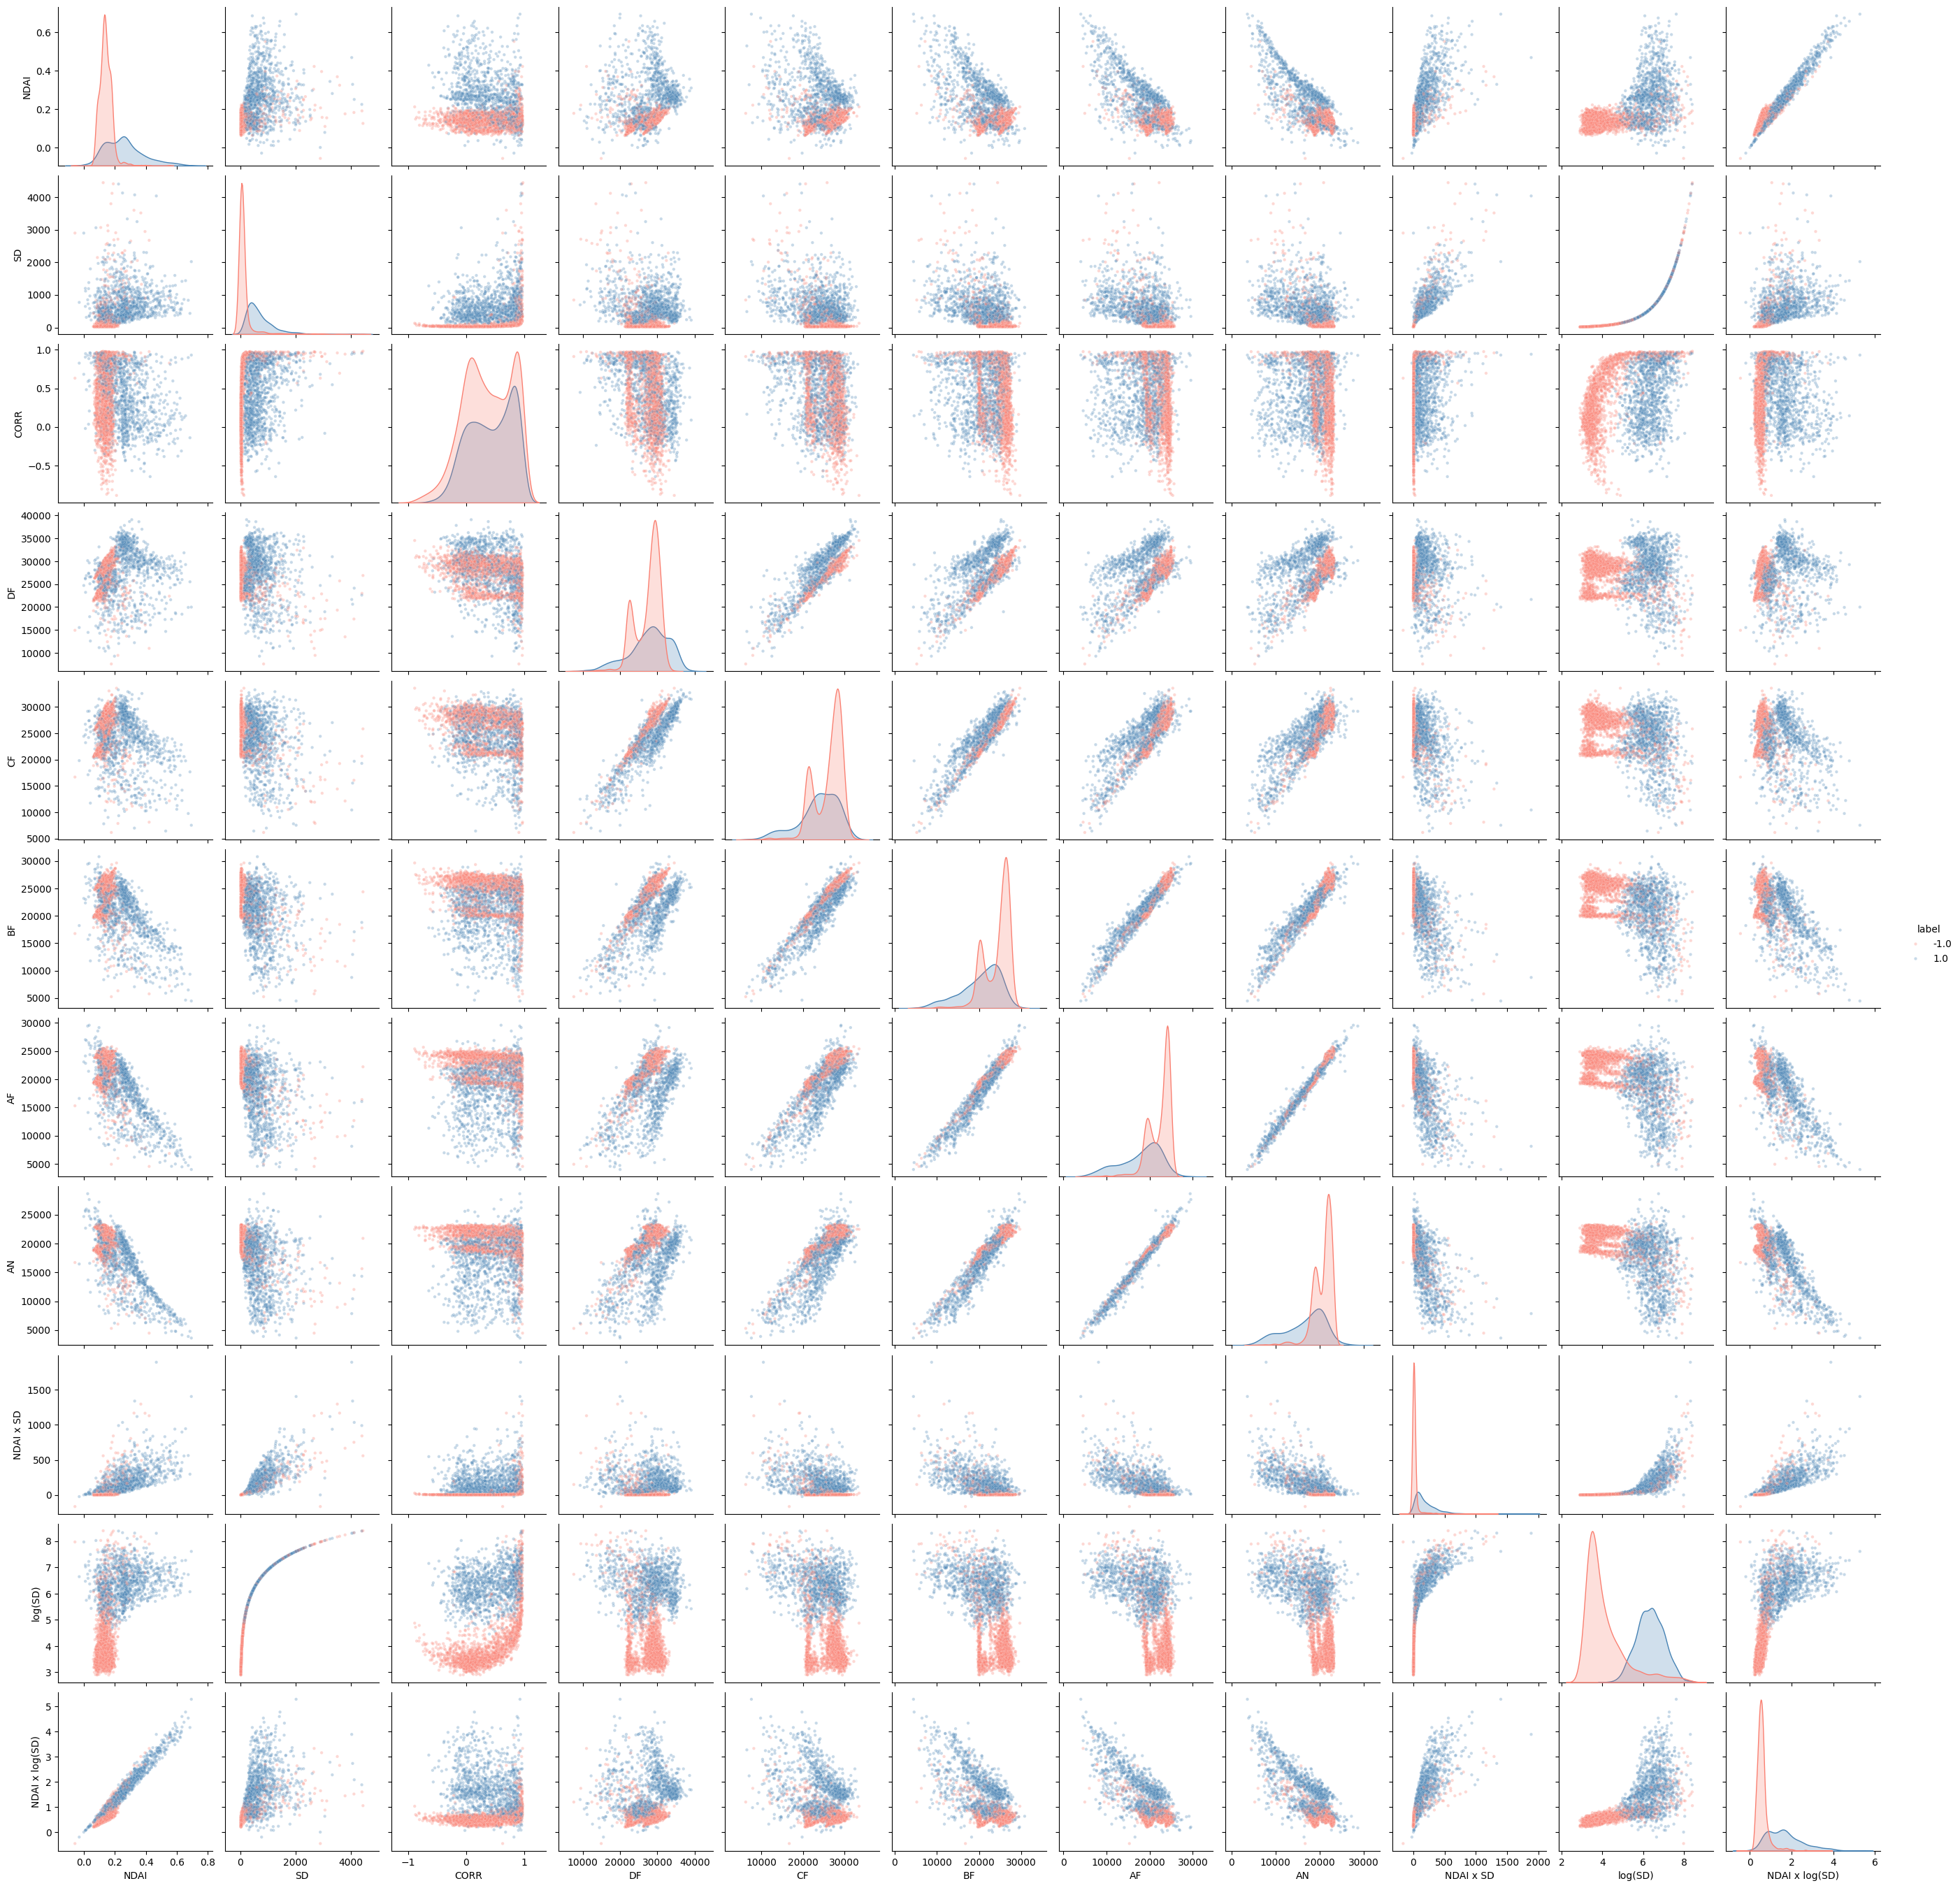

In [19]:
# Setup
features = ['NDAI', 'SD', 'CORR', 'DF', 'CF', 'BF', 'AF', 'AN']

# Feature Engineering
# eda_df['angular_diff'] = eda_df['DF'] - eda_df['AN']
# eda_df['angular_ratio'] = np.log(eda_df['DF'] / eda_df['AN'])
eda_df['NDAI x SD'] = eda_df['NDAI'] * eda_df['SD']
eda_df['log(SD)'] = np.log(eda_df['SD'] + 1)
eda_df['NDAI x log(SD)'] = eda_df['NDAI'] * eda_df['log(SD)']

features_engineered = features + [ 'NDAI x SD', 'log(SD)', 'NDAI x log(SD)']

d = eda_df[eda_df["label"] != 0]
f = d["label"]
clouds_df = d[d['label'] == 1]
no_clouds_df = d[d['label'] == -1]


# Pairplot
sample = d[features_engineered + ['label']].sample(3000, random_state=15)
sns.pairplot(sample, hue='label', 
             palette={1: 'steelblue', -1: 'salmon'},
             plot_kws={'alpha': 0.3, 's': 10})
plt.show()


In [20]:
# AUC Scores
results = []
for feat in features_engineered:
    feature = d[feat]
    score = roc_auc_score(f, feature)
    score = max(score, 1 - score)
    results.append(score)

auc_df = pd.DataFrame({
    "Feature": features_engineered, 
    "AUC": results
}).sort_values(by=['AUC'], ascending=False)

# Glass Delta
glassd_results = []
for feat in features_engineered:
    mean_cloud = clouds_df[feat].mean()
    mean_nocloud = no_clouds_df[feat].mean()
    std_cloud = clouds_df[feat].std()
    std_nocloud = no_clouds_df[feat].std()
    #pooled_std = np.sqrt((std_cloud**2 + std_nocloud**2) / 2)
    glass_d = (mean_cloud - mean_nocloud) / std_nocloud
    glassd_results.append({'Feature': feat, 'Glass_d': round(glass_d, 3)})

glass_df = pd.DataFrame(glassd_results).sort_values(
    by='Glass_d', 
    ascending=False
)

# Combined Summary Table
summary_df = auc_df.merge(glass_df, on='Feature')
print(summary_df)

           Feature       AUC  Glass_d
0        NDAI x SD  0.944013    1.548
1          log(SD)  0.935122    2.105
2               SD  0.935122    1.264
3   NDAI x log(SD)  0.922885    3.220
4             NDAI  0.823382    2.816
5               AF  0.799156   -1.485
6               AN  0.793544   -1.602
7               BF  0.770345   -1.143
8               CF  0.642784   -0.612
9               DF  0.554394    0.156
10            CORR  0.523656    0.111


### Engineered Features & Motivation for them

1. **NDAI x SD**
    - both capture different aspects of cloud structure. High values of both simultaneously might be a very strong cloud signal. 

2. **Log(SD)**
    - helps combat the outliers within the SD values. It also yielded better glass delta score, while having the same AUC as SD. So it didn't improve on seperating the negative & positive class by rank, but it did improve the standardized mean difference between classes. This suggests the log transformation improves the statistical properties of SD without sacrificing predictive power (to rank cloud pixels above clear pixels). *Univariate measure*.

     - Note: Log(SD) did remarkably improve on seperating the classes over SD in the pairplot *(bivariate measure--> works better with other vairbales.)*
     - Why use it for modeling? --> It produces better behaved inputs for classifiers that are sensitive to extreme values like logistic regression & SVM.

3. **NDAI x log(SD)**
    - Our top feature based on univariate measures was NDAI * log(SD) so I created this feature to use for outlier-sensitive models. It performed slightly less better than AUC in original NDAI * log(SD) feature, but it had a notably increased Glass Delta score meaning it the typical cloud pixel has an NDAI x log_SD value that exceeds 99.7% of typical clear pixel values (3 SD aways --> strong seperation).

    
#### These features should be adjusted based on the model we're using:

- **Logistic Regression and SVM** — very sensitive to scale and outliers. These models benefit most from log(SD) over raw SD. Also hurt most by multicollinearity — so having both SD and log(SD) would be problematic. Pick one — log(SD).
- **Random Forest and Tree Based Models** — essentially immune to scale and outliers since they split on thresholds. Raw SD works fine. Also handle multicollinearity naturally by just picking one of the correlated features. Keep everything and let the model decide.
- **Neural Networks** — sensitive to scale but handle complex interactions automatically. Log(SD) preferred but the model will partially compensate either way.

### Multicollinearity & Outlier Check with Engineered Features:

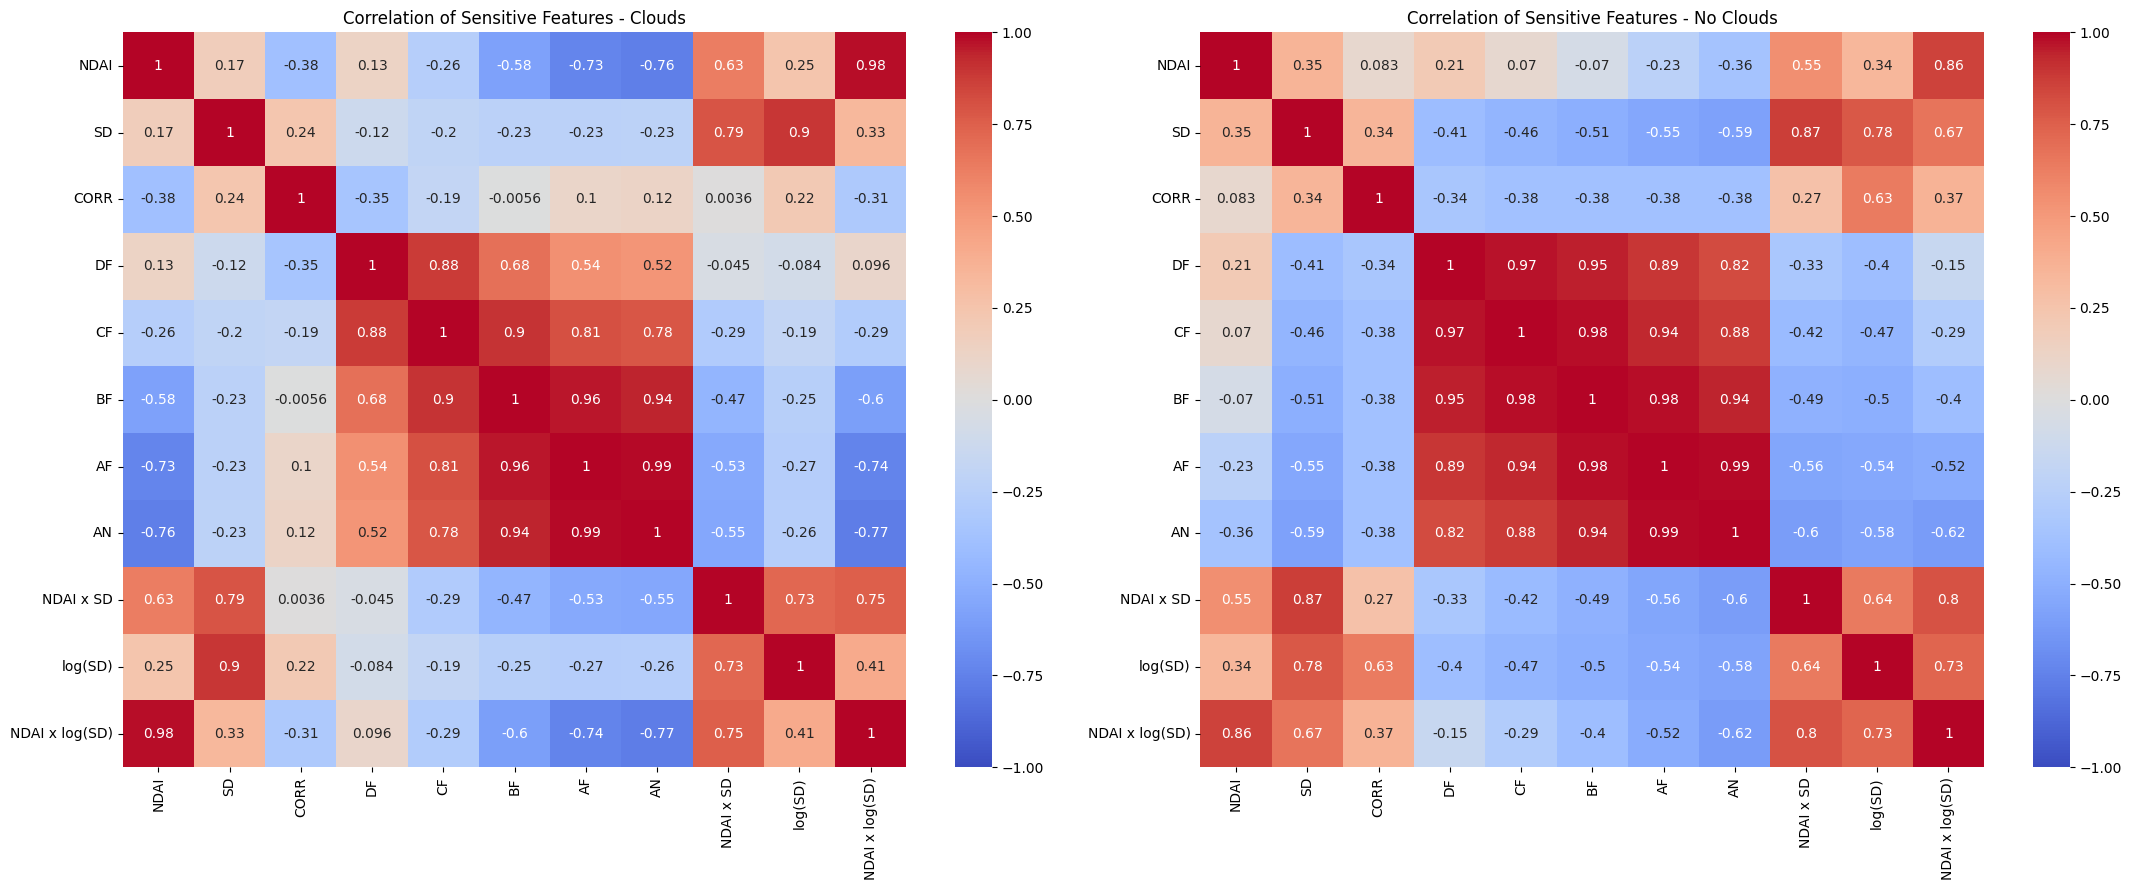

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, df_class, title in zip(axes,
                                [clouds_df, no_clouds_df],
                                ["Clouds", "No Clouds"]):
    sns.heatmap(df_class[features_engineered].corr(), cmap="coolwarm", 
                annot=True, center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Correlation of Sensitive Features - {title}")
plt.tight_layout()
plt.show()

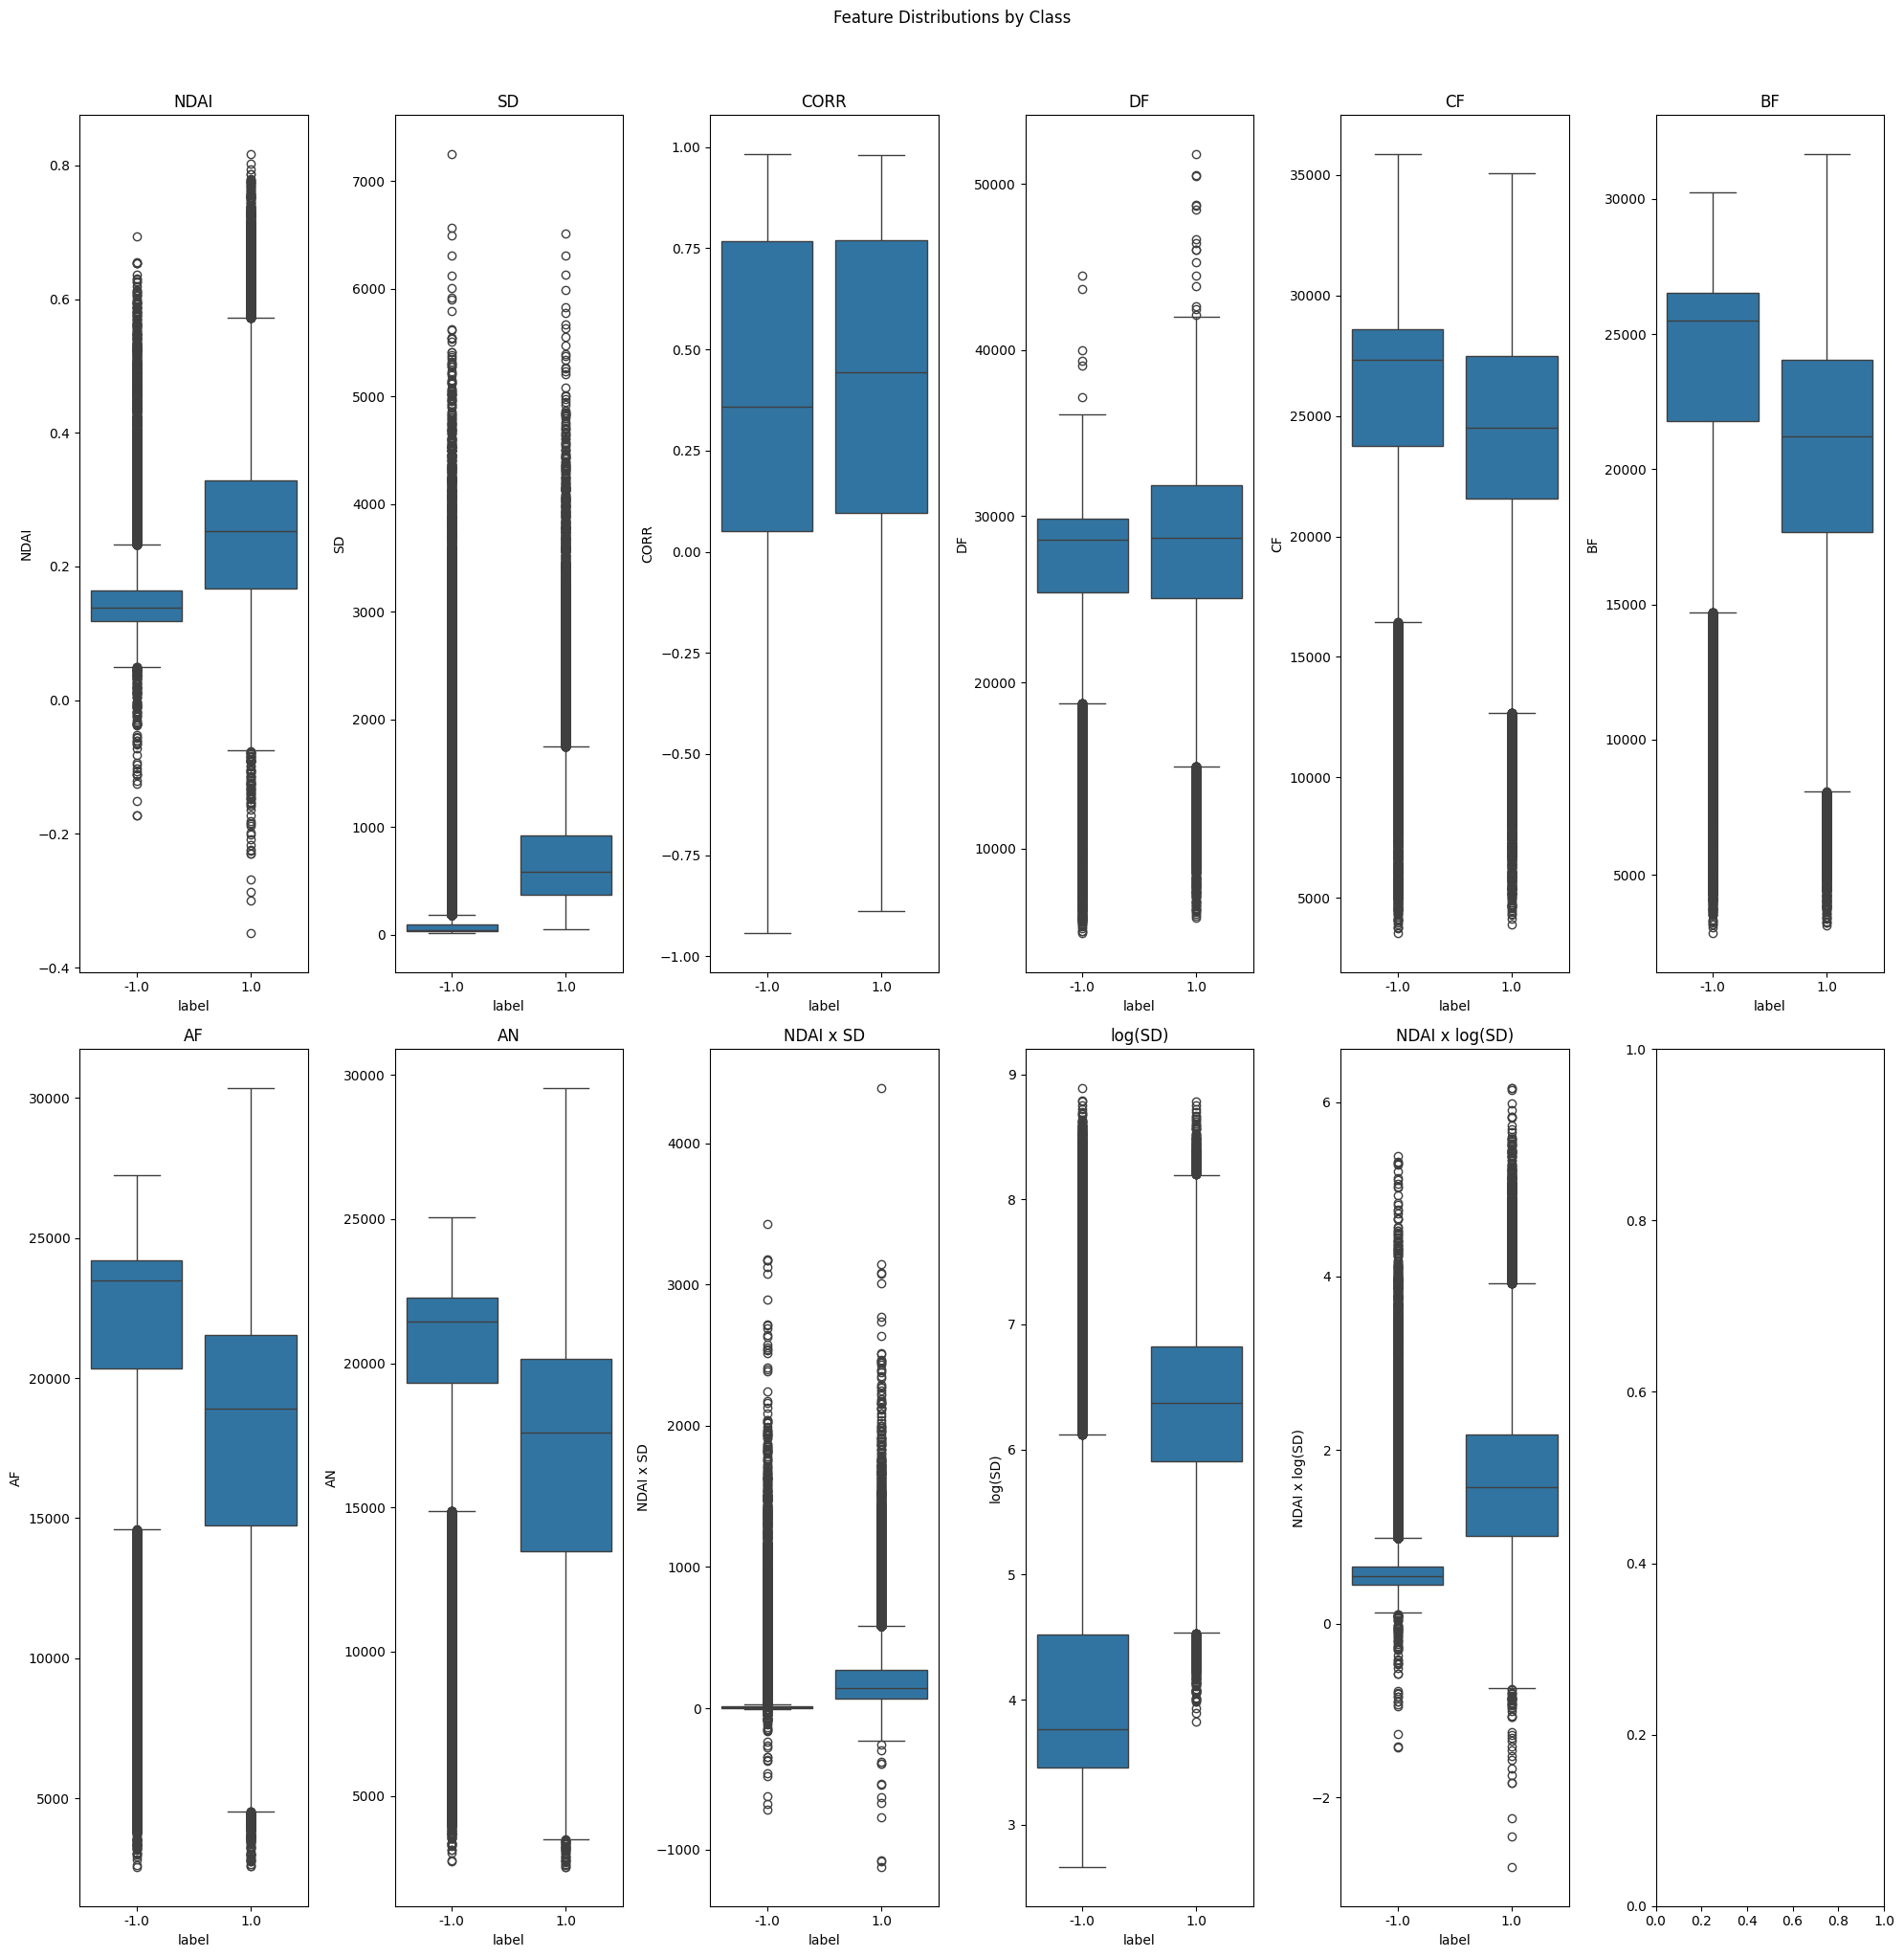

In [22]:
df = pd.concat([clouds_df, no_clouds_df])

fig, axes = plt.subplots(2, 6, figsize=(20, 20))
for ax, feat in zip(axes.flatten(), features_engineered):
    sns.boxplot(data=df[df['label'] != 0], x='label', y=feat, ax=ax)
    ax.set_title(feat)
plt.suptitle("Feature Distributions by Class", y=1.02)
plt.tight_layout()
plt.show()

This visualization proves that Log(SD) addresses outlier issue in SD.

## **Final Feature Reccommendation:**

**For outlier & multicollinearity sensitive models (Logistic Regression & SVM):**
- NDAI
- log(SD)
- CORR
- AN*
- NDAI x log(SD)**

**Out of all radiance angles, AN gave the highest metrics. So I chose this and dropped the others to also avoid multicollinearity*
***NDAI x log(SD) was our strongest engineered feature by Glass's delta (3.220) but correlates 0.98 with NDAI in cloud pixels & 0.86 in no clouds. If added to sensitive models, monitor for coefficient instability. Recommend testing with and without it. (JUDGEMENT CALL)*

**For robust models (RandomForest, NN's):**
- NDAI
- SD*
- CORR
- AF
- AN
- BF
- NDAI x SD*

**If using Nueral Networks might be best to use log scaled SD & standardize features as they are sensitive to scale.*


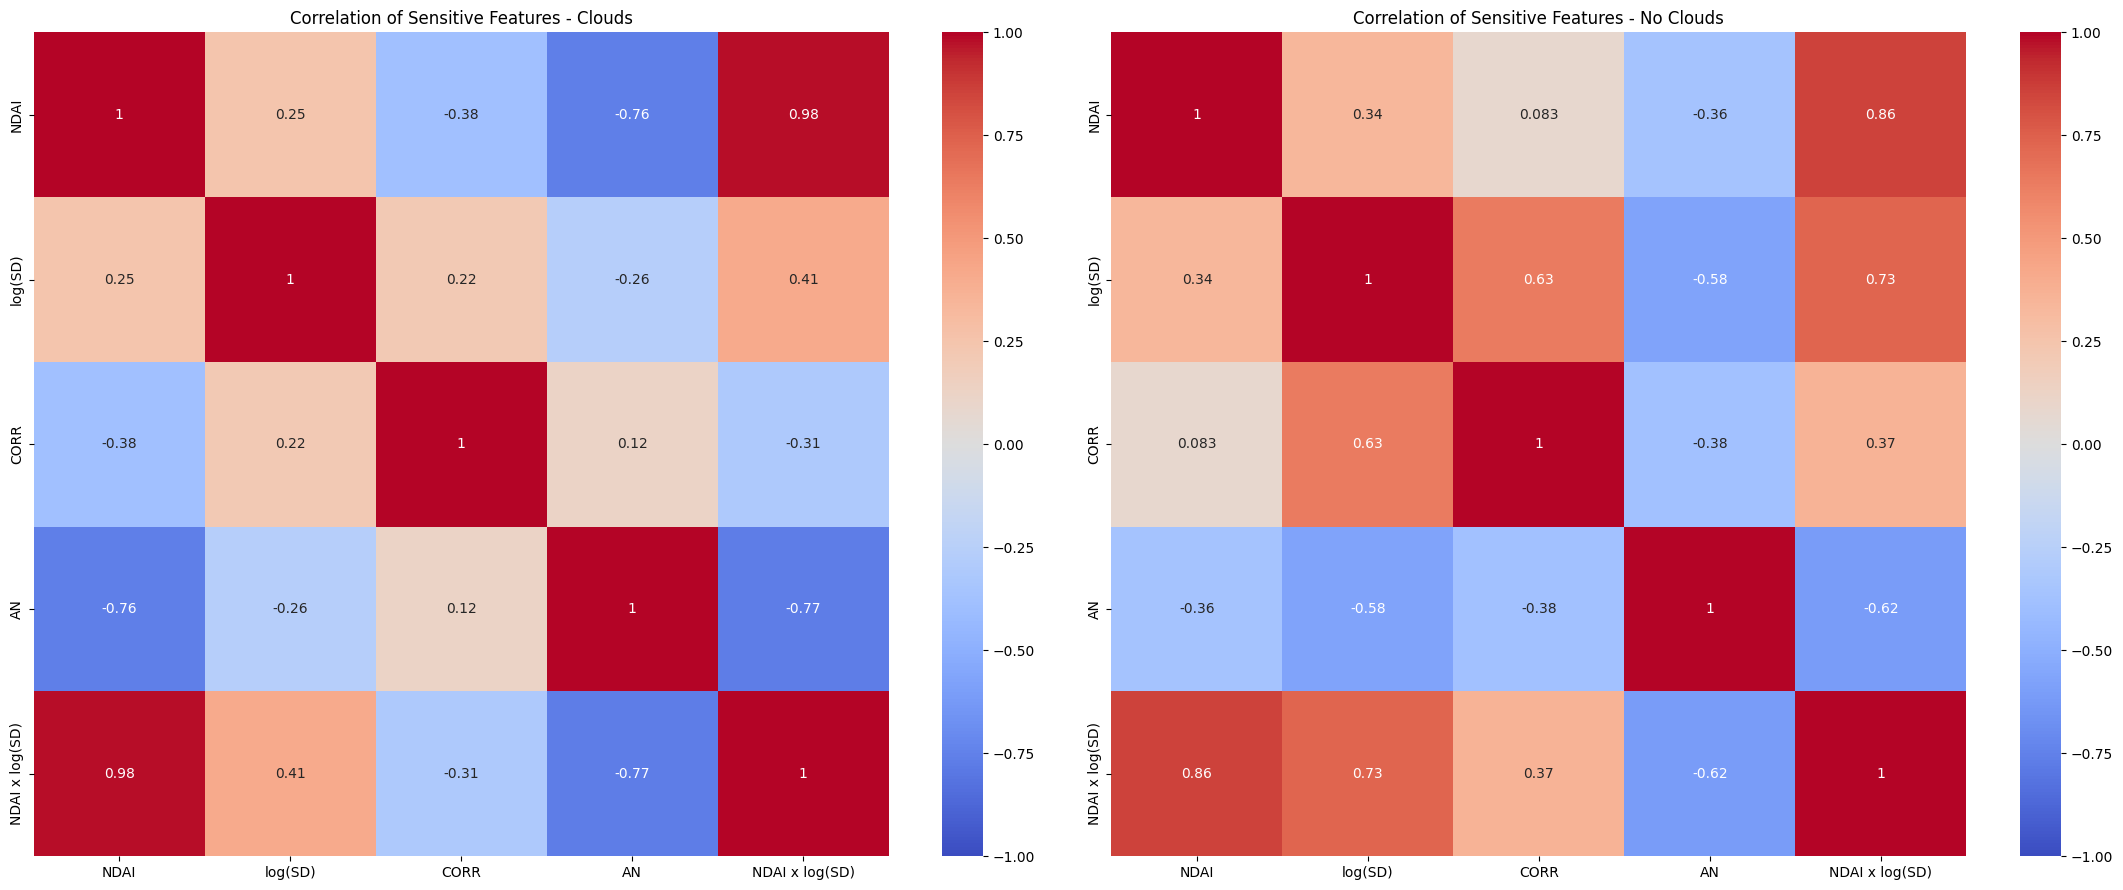

In [23]:
# For sensitive models (logistic regression, SVM) --> Want to be more mindful of multicollinerity & watch for scale & outliers
features_sensitive = ['NDAI', 'log(SD)', 'CORR', 'AN', 'NDAI x log(SD)']  ### JUDGEMENT CALL: Keep "NDAI x log(SD)" & monitor coefficients or drop & keep them seperate.

# For robust models (random forest, neural networks) --> dropped CF, DF both were weak in AUC/Glass scores & pair plot seperation.
features_robust = ['NDAI', 'SD', 'CORR', 'AF', 'AN', 'BF', 'NDAI x SD']


fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, df_class, title in zip(axes,
                                [clouds_df, no_clouds_df],
                                ["Clouds", "No Clouds"]):
    sns.heatmap(df_class[features_sensitive].corr(), cmap="coolwarm", 
                annot=True, center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Correlation of Sensitive Features - {title}")
plt.tight_layout()
plt.show()

# Correlation between robust features isn't an important metric
# fig, axes = plt.subplots(1, 2, figsize=(22, 9))
# for ax, df_class, title in zip(axes,
#                                 [clouds_df, no_clouds_df],
#                                 ["Clouds", "No Clouds"]):
#     sns.heatmap(df_class[features_robust].corr(), cmap="coolwarm", 
#                 annot=True, center=0, vmin=-1, vmax=1, ax=ax)
#     ax.set_title(f"Correlation of Robust Features - {title}")
# plt.tight_layout()
# plt.show()

## Step 3: Test-Train-Split Exploration

Checking the proportions of clouds to infer on what to use for train-test split. *Do we want the model to be trained on similar data or different looking data based on proporitons?*

In [24]:
for img_name, img_df in [('3490', df_3490), ('3257', df_3257), ('2791', df_2791)]:
    labeled = img_df[img_df['label'] != 0]
    prop = (labeled['label'] == 1).mean()
    print(f"Image {img_name}: {prop:.3f} proportion clouds")

Image 3490: 0.478 proportion clouds
Image 3257: 0.289 proportion clouds
Image 2791: 0.388 proportion clouds


Two Different Ways To Think About It:

Option A — Train on 3257 + 3490, Test on 2791
- Training on the most diverse pair (29% vs 48% clouds). Test image 2791 at 39% sits right in the middle of the training distribution. This model has seen both more and less cloudy images, so 2791 shouldn't be too surprising.
Option B — Train on 3490 + 2791, Test on 3257

- Testing on the least cloudy image (29%). This is arguably a harder test — the model trained on moderately cloudy images and now has to perform on something quite different. This better reflects real world challenges where future images might look different from training data.